# Fundamentals of Data Science: Matplotlib Practice

This one class worksheet is structured for collaborative coding. Work to complete the following visualization exercises using the matplotlib library. Please refer to matplotlib demo code posted on iCollege. 


## Part 1: The Object-Oriented Interface & Line Plots (20 Minutes)
* Initialize a figure and axes using `fig, ax = plt.subplots()`.
* Plot $y = x^2$ and $y = x^3$ on the same axes for a set of $x$ values. 
* Assign a unique format string to each line, such as `'.-r'` for a red dotted line and `'b'` for a solid blue line.
* Use the `label` keyword argument inside the plot function and call `ax.legend()` to dynamically generate the legend without mislabeling.
* Add a descriptive title, X and Y axis labels, and enable the background grid using `ax.grid(True)`.

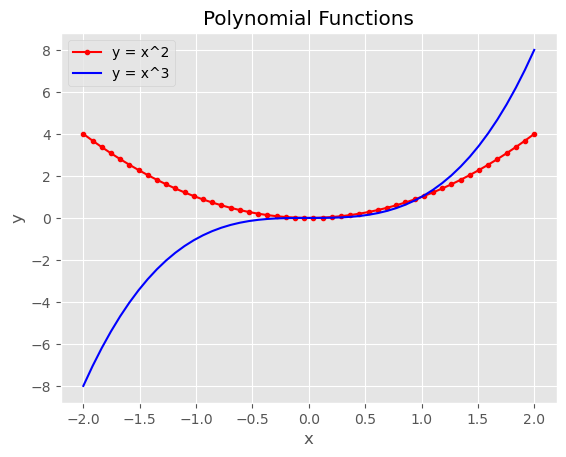

In [40]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-2, 2, 50)
fig, ax = plt.subplots()
ax.plot(x, x**2, '.-r', label='y = x^2')
ax.plot(x, x**3, 'b', label='y = x^3')
ax.set_title('Polynomial Functions')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.grid(True)
ax.legend()
plt.show()

## Part 2: Subplots & Categorical Data (25 Minutes)
* Create a 2x2 grid of subplots using `fig, axs = plt.subplots(2, 2)`.
* **Top-Left:** Generate a scatter plot using `.scatter()` with custom marker colors, `alpha` for transparency, and black `edgecolors`.
* **Top-Right:** Construct a vertical stacked bar chart by plotting a base dataset, then plotting a second dataset using the `bottom` parameter to stack it.
* **Bottom-Left:** Create a pie chart comparing four categories, utilizing `autopct='%.2f%%'` to display percentage values and `startangle=90` to rotate the wedges.

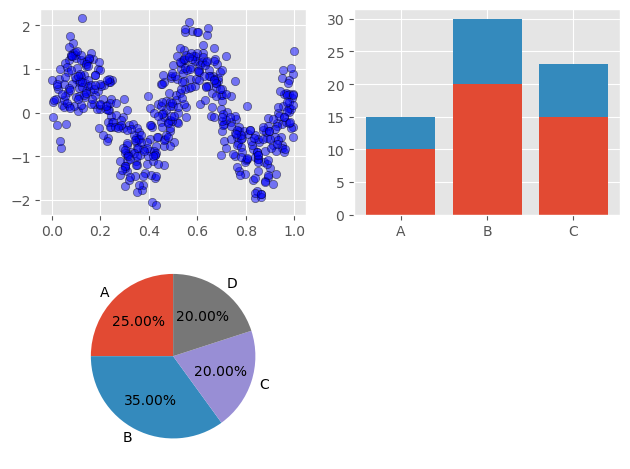

In [41]:
fig, axs = plt.subplots(2, 2)

np.random.seed(137)

x = np.random.rand(500)
y = np.sin(13*x) + np.random.normal(0, 0.5, 500)
axs[0, 0].scatter(x, y, color='blue', alpha=0.5, edgecolors='black')

categories = ['A', 'B', 'C']
d1 = [10, 20, 15]
d2 = [5, 10, 8]
axs[0, 1].bar(categories, d1)
axs[0, 1].bar(categories, d2, bottom=d1)

axs[1, 0].pie([25, 35, 20, 20], labels=['A', 'B', 'C', 'D'], autopct='%.2f%%', startangle=90)

axs[1, 1].axis('off')

plt.tight_layout()
plt.show()

## Part 3: Distributions, Styling, & Exporting (20 Minutes)
* Apply a predefined stylesheet to the session using `plt.style.use()` to instantly improve the aesthetics of the plots.
* Generate an array using `np.random.randn()` and visualize the distribution with a histogram using `.hist()`, explicitly defining the `bins` and `edgecolor`.
* Create a boxplot comparing two distinct datasets to visualize the medians, interquartile ranges, and outliers.
* Manually restrict the visible range of the data using `plt.axis([xmin, xmax, ymin, ymax])` or by handling the X and Y ticks directly.
* Export the final figure using `fig.savefig('practice_plot.png', dpi=300, bbox_inches="tight")` to ensure high resolution and optimized whitespace.

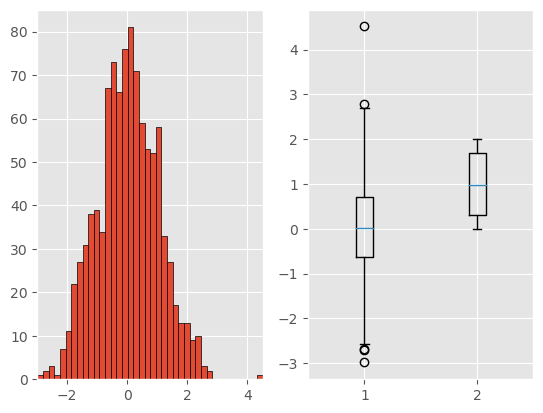

In [42]:
plt.style.use('ggplot')

fig, (ax1, ax2) = plt.subplots(1, 2)

np.random.seed(137)

data1 = np.random.randn(1000)
data2 = 1-np.sin(13*np.random.randn(1000)) 

ax1.hist(data1, bins=40, edgecolor='black')
plt.sca(ax1)
plt.axis([np.min(data1), np.max(data1), min(ax1.get_ylim()), max(ax1.get_ylim())])

ax2.boxplot([data1, data2])

fig.savefig('practice_plot.png', dpi=300, bbox_inches="tight")
plt.show()

## Part 4: Advanced Formatting & Error Bars (20 Minutes)
* **Horizontal Bar Charts:** Construct a horizontal bar chart utilizing `.barh()` to compare five categories. 
* **Decluttering the Axes:** Remove the chart frame entirely using `ax.set_frame_on(False)` and hide the x-axis tick marks by passing an empty list to `ax.set_xticks([])`.
* **Dynamic Text Placement:** Iterate through the generated bars to retrieve their numerical values using `bar.get_width()`[cite: 1]. Use `ax.text()` to programmatically place the exact value label slightly to the right of each bar's edge.
* **Error Bar Implementation:** Visualize variability in repeated observations by generating a decaying exponential curve defined by $y = \exp(-x)$ and plotting it with the `.errorbar()` function.
* **Customizing Uncertainty:** Pass an array of random noise to the `yerr` parameter to represent the uncertainty. Style the caps of the error bars by explicitly setting the `capsize` and `capthick` parameters, and apply a format string like `fmt='.-r'` to change the main line's color and marker.

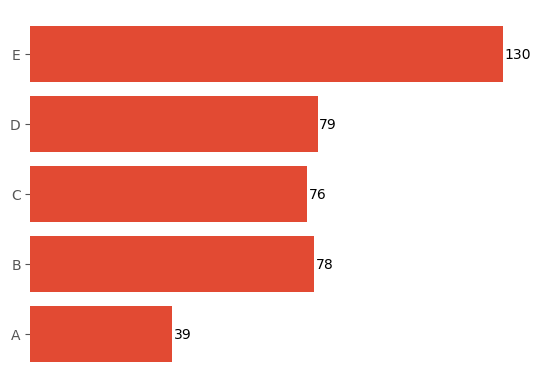

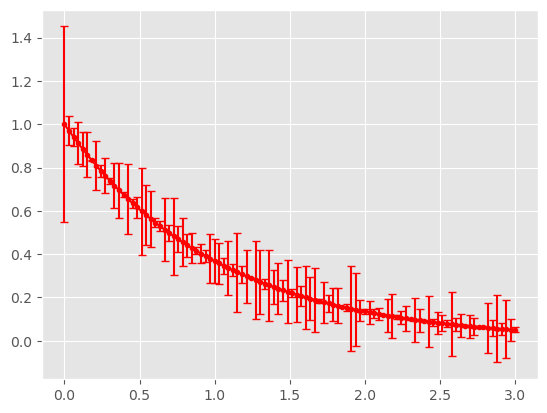

In [43]:
np.random.seed(137)

fig, ax = plt.subplots()
categories = ['A', 'B', 'C', 'D', 'E']
values = np.random.randint(1, 137, len(categories))
bars = ax.barh(categories, values)
ax.set_frame_on(False)
ax.set_xticks([])
for bar in bars:
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, str(bar.get_width()), va='center')
plt.show()

fig, ax = plt.subplots()
x = np.linspace(0, 3, 100)
y = np.exp(-x)
yerr = abs(np.random.randn(len(x)) * 0.1)
ax.errorbar(x, y, yerr=yerr, fmt='.-r', capsize=3, capthick=1)
plt.show()

## Part 5: Advanced Colors, Tick Handling, & Legends (20 Minutes)
* **Multiple Color Specifications:** Plot three distinct sine/cosine waves, specifying their colors using three different methods: a hexadecimal string (e.g., `'#FF00FF'`), an RGB tuple (e.g., `(0.2, 0.1, 0)`), and a grayscale intensity string (e.g., `'0.5'`).
* **Line Styles:** Differentiate the curves by applying distinct line styles such as dashed (`'--'`), dash-dot (`'-.'`), and dotted (`':'`).
* **Custom Ticks:** Pass explicit lists of coordinates to `plt.xticks()` and `plt.yticks()` to customize the tick locations on both axes.
* **Legend Placement:** Add a legend and manually adjust its placement using the `loc` parameter with numerical codes (e.g., setting `loc=2` to force the legend into the upper left corner).

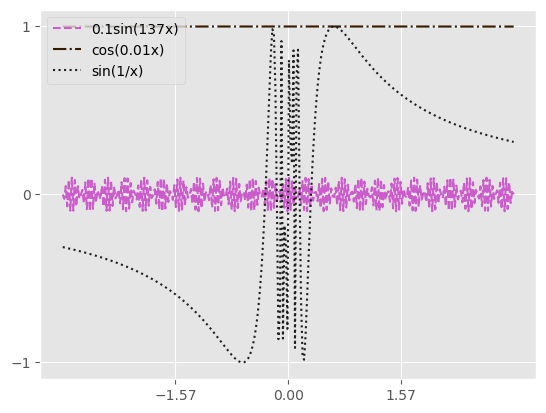

In [44]:
x = np.linspace(-1*np.pi, 1 * np.pi, 300)

plt.plot(x, 0.1*np.sin(137*x), color="#CC5BCC", linestyle='--', label='0.1sin(137x)')
plt.plot(x, np.cos(0.01*x), color=(0.2, 0.1, 0), linestyle='-.', label='cos(0.01x)')
plt.plot(x, np.sin(1/x), color='0.12', linestyle=':', label='sin(1/x)')

plt.xticks([0, np.pi/2, -np.pi/2])
plt.yticks([-1, 0, 1])
plt.legend(loc=2)
plt.show()